# Regresión Logística – Ejercicio Aplicado
## ¿Va a pagar o no? Predicción del riesgo de impago en solicitudes de crédito

**Autor:** Jonnathan Pazos
**Universidad de Cundinamarca – CADI INTRODUCCIÓN A MACHINE LEARNIGN**
**Herramientas:** Python, Google Colab, Pandas, NumPy, Matplotlib y Scikit-learn

---

**Contenido del notebook**

1. Planteamiento del problema
2. Carga y descripción de los datos
3. Exploración rápida
4. Preparación de los datos
5. División en entrenamiento y prueba
6. Implementación del modelo
7. Predicciones con `predict()` y `predict_proba()`
8. Evaluación del modelo
9. Ajuste del umbral de decisión
10. Interpretación de coeficientes (odds ratios)
11. Análisis de errores
12. Conclusiones
13. Referencias

## 1. Planteamiento del problema

Cuando una entidad financiera recibe una solicitud de crédito tiene que decidir si la aprueba o no. Si aprueba a un cliente que después no paga, pierde el dinero prestado; si rechaza a un buen cliente, pierde el negocio.

**Pregunta del ejercicio:** con la información que el cliente entrega al momento de la solicitud (edad, ingresos, gastos, tipo de trabajo, vivienda, monto pedido, etc.), ¿se puede estimar la **probabilidad de que no pague** el crédito?

**¿Por qué Regresión Logística?**

- La variable que queremos predecir es **binaria**: el cliente *paga* (0) o *incumple* (1). Es un problema de clasificación.
- El modelo no solo dice "sí" o "no": entrega una **probabilidad de incumplimiento**, que el banco puede usar para fijar su propia política (por ejemplo, rechazar si la probabilidad pasa de cierto valor).
- Los coeficientes se pueden leer como **odds ratios**, así que se puede explicar *por qué* un cliente salió riesgoso. En crédito esto es importante porque las decisiones deben poder justificarse.
- Es el modelo clásico del *credit scoring* y sirve como línea base antes de probar modelos más complejos.

In [45]:
# Librerías del curso
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Scikit-learn: división de datos, preparación, modelo y métricas
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                            classification_report, roc_auc_score, roc_curve)

# Para que los resultados sean reproducibles
SEMILLA = 42
np.random.seed(SEMILLA)

# Colores que se usan en todos los gráficos
COLOR_PAGA = "#4C72B0"
COLOR_INCUMPLE = "#DD8452"
plt.rcParams["figure.dpi"] = 100

## 2. Carga y descripción de los datos

**Fuente:** conjunto de datos *Credit Scoring* (4.455 solicitudes de crédito de una entidad financiera), publicado por Gaston Sánchez en GitHub a partir del curso de minería de datos del profesor Tomàs Aluja (Universitat Politècnica de Catalunya).
Enlace: https://github.com/gastonstat/CreditScoring

| Variable original | Significado | Tipo |
|---|---|---|
| Status | Estado del crédito: 1 = bueno (pagó), 2 = malo (incumplió) | **Objetivo** |
| Seniority | Antigüedad en el trabajo (años) | Numérica |
| Home | Tipo de vivienda (alquiler, propia, familiar, etc.) | Categórica |
| Time | Plazo del crédito solicitado (meses) | Numérica |
| Age | Edad del cliente | Numérica |
| Marital | Estado civil | Categórica |
| Records | ¿Tiene antecedentes (reportes) previos? | Categórica |
| Job | Tipo de trabajo (fijo, medio tiempo, independiente, otro) | Categórica |
| Expenses | Gastos | Numérica |
| Income | Ingresos | Numérica |
| Assets | Activos (patrimonio) | Numérica |
| Debt | Deuda actual | Numérica |
| Amount | Monto del crédito solicitado | Numérica |
| Price | Precio del bien que se quiere financiar | Numérica |

**Variable objetivo:** `incumple` = 1 si el crédito terminó como *malo* (Status = 2) y 0 si fue *bueno* (Status = 1).

In [46]:
# Se carga el CSV directamente desde GitHub.
# Si no hay internet, se usa la copia local que está en el repositorio.
URL = "https://raw.githubusercontent.com/gastonstat/CreditScoring/master/CreditScoring.csv"
try:
    df_raw = pd.read_csv(URL)
except Exception:
    df_raw = pd.read_csv("CreditScoring.csv")

print("Filas y columnas:", df_raw.shape)
df_raw.head()

Filas y columnas: (4455, 14)


,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


In [47]:
# Resumen estadístico de las variables (todas vienen como números)
df_raw.describe().round(1)

,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
count,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0
mean,1.3,8.0,2.7,46.4,37.1,1.9,1.2,1.7,55.6,763317.0,1060340.8,404382.0,1039.0,1462.9
std,0.5,8.2,1.6,14.7,11.0,0.6,0.4,1.0,19.5,8703625.3,10217568.7,6344253.4,474.5,628.1
min,0.0,0.0,0.0,6.0,18.0,0.0,1.0,0.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,1.0,2.0,2.0,36.0,28.0,2.0,1.0,1.0,35.0,80.0,0.0,0.0,700.0,1117.5
50%,1.0,5.0,2.0,48.0,36.0,2.0,1.0,1.0,51.0,120.0,3500.0,0.0,1000.0,1400.0
75%,2.0,12.0,4.0,60.0,45.0,2.0,1.0,3.0,72.0,166.0,6000.0,0.0,1300.0,1692.0
max,2.0,48.0,6.0,72.0,68.0,5.0,2.0,4.0,180.0,99999999.0,99999999.0,99999999.0,5000.0,11140.0


**Lo que se ve en el resumen:**

- Las variables categóricas (Home, Marital, Job, Records) vienen **codificadas con números**, hay que traducirlas.
- `Income`, `Assets` y `Debt` tienen un máximo de **99.999.999**, que no es un valor real: es el código que usa la fuente para **dato faltante**.
- En las categóricas y en `Status` el valor **0** también significa dato faltante.

In [48]:
# Cuántos datos faltantes "escondidos" hay
print("Valores 99999999 (faltante) por columna:")
print((df_raw == 99999999).sum()[lambda s: s > 0])

print("\nValores 0 (faltante) en las categóricas y en Status:")
print((df_raw[["Status", "Home", "Marital", "Job"]] == 0).sum())

print("\nClientes con ingresos = 0:", (df_raw["Income"] == 0).sum())

Valores 99999999 (faltante) por columna:
Income    34
Assets    47
Debt      18
dtype: int64

Valores 0 (faltante) en las categóricas y en Status:
Status     1
Home       6
Marital    1
Job        2
dtype: int64

Clientes con ingresos = 0: 347


## 3. Exploración rápida

Antes de modelar se revisa cómo está repartida la variable objetivo y si hay variables que a simple vista se relacionen con el incumplimiento.

              clientes     %
Status                      
Paga (0)          3200  71.8
Incumple (1)      1254  28.2


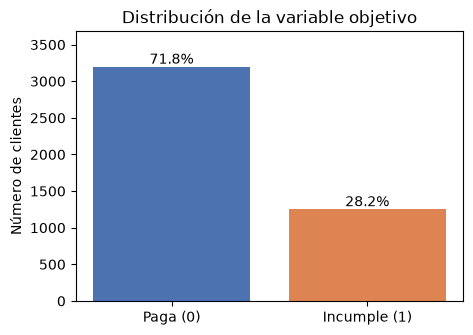

In [49]:
# Distribución de la variable objetivo (sin la fila que no tiene Status)
conteo = df_raw.loc[df_raw["Status"] != 0, "Status"].map({1: "Paga (0)", 2: "Incumple (1)"}).value_counts()
porc = (conteo / conteo.sum() * 100).round(1)
print(pd.DataFrame({"clientes": conteo, "%": porc}))

fig, ax = plt.subplots(figsize=(5, 3.5))
barras = ax.bar(conteo.index, conteo.values, color=[COLOR_PAGA, COLOR_INCUMPLE])
for b, p in zip(barras, porc.values):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 40, f"{p}%", ha="center")
ax.set_title("Distribución de la variable objetivo")
ax.set_ylabel("Número de clientes")
ax.set_ylim(0, conteo.max() * 1.15)
plt.show()

Aproximadamente **7 de cada 10** clientes pagan y **3 de cada 10** incumplen. Las clases están algo desbalanceadas, así que **el accuracy por sí solo puede engañar**: un modelo que diga siempre "paga" ya acertaría cerca del 72 %. Por eso más adelante se miran también Precision, Recall y F1.

## 4. Preparación de los datos

Pasos:

1. Quitar la fila sin variable objetivo (Status = 0).
2. Crear la variable objetivo `incumple` (1 = incumple, 0 = paga).
3. Marcar como `NaN` los faltantes codificados (99999999 y los 0 de las categóricas). Un ingreso de 0 tampoco tiene sentido en alguien que pide un crédito, así que también se trata como faltante.
4. Traducir los códigos de las categóricas a texto.
5. Crear una variable nueva: **% de financiación** = monto pedido / precio del bien × 100.
6. Renombrar las columnas a español.

La **imputación de faltantes**, el **one-hot encoding** y el **escalado** se hacen más adelante dentro de un `Pipeline`, para que se calculen **solo con los datos de entrenamiento** y no se filtre información del conjunto de prueba.

In [50]:
df = df_raw.copy()

# 1. Fila sin variable objetivo
df = df[df["Status"] != 0].copy()

# 2. Variable objetivo: 1 = incumple (Status 2), 0 = paga (Status 1)
df["incumple"] = (df["Status"] == 2).astype(int)
df = df.drop(columns="Status")

# 3. Faltantes codificados -> NaN
for col in ["Income", "Assets", "Debt"]:
    df[col] = df[col].replace(99999999, np.nan)
df.loc[df["Income"] == 0, "Income"] = np.nan

# 4. Códigos -> texto (el 0 no está en el diccionario, así que queda como NaN)
mapas = {
    "Home":    {1: "alquiler", 2: "propia", 3: "privada", 4: "ignorado", 5: "con_padres", 6: "otra"},
    "Marital": {1: "soltero", 2: "casado", 3: "viudo", 4: "separado", 5: "divorciado"},
    "Records": {1: "no", 2: "si"},
    "Job":     {1: "fijo", 2: "medio_tiempo", 3: "independiente", 4: "otro"},
}
for col, m in mapas.items():
    df[col] = df[col].map(m)

# 5. Variable nueva: qué porcentaje del bien se está financiando
df["Financiacion_pct"] = 100 * df["Amount"] / df["Price"]

# 6. Nombres en español
df = df.rename(columns={
    "Seniority": "antiguedad_laboral", "Home": "vivienda", "Time": "plazo_meses",
    "Age": "edad", "Marital": "estado_civil", "Records": "antecedentes",
    "Job": "tipo_trabajo", "Expenses": "gastos", "Income": "ingresos",
    "Assets": "activos", "Debt": "deuda", "Amount": "monto_solicitado",
    "Price": "precio_bien", "Financiacion_pct": "financiacion_pct"})

print("Tamaño después de limpiar:", df.shape)
print("\nDatos faltantes por columna:")
print(df.isna().sum()[lambda s: s > 0])

Tamaño después de limpiar: (4454, 15)

Datos faltantes por columna:
vivienda          6
estado_civil      1
tipo_trabajo      2
ingresos        381
activos          47
deuda            18
dtype: int64


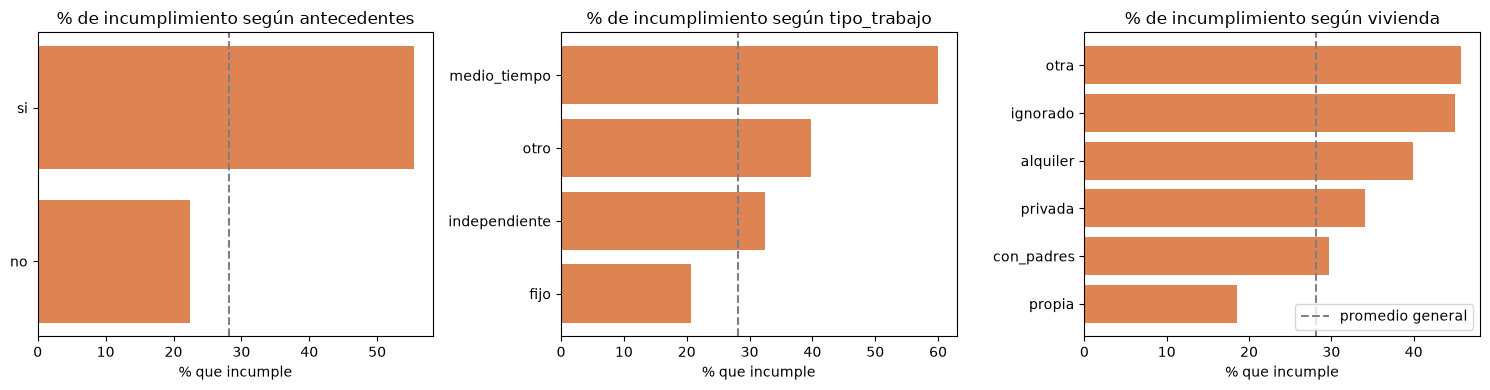

In [51]:
# ¿Qué variables parecen relacionarse con el incumplimiento?
# Tasa de incumplimiento (%) por categoría
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["antecedentes", "tipo_trabajo", "vivienda"]):
    tasa = (df.groupby(col)["incumple"].mean() * 100).sort_values()
    ax.barh(tasa.index, tasa.values, color=COLOR_INCUMPLE)
    ax.axvline(df["incumple"].mean() * 100, color="gray", ls="--", label="promedio general")
    ax.set_title(f"% de incumplimiento según {col}")
    ax.set_xlabel("% que incumple")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

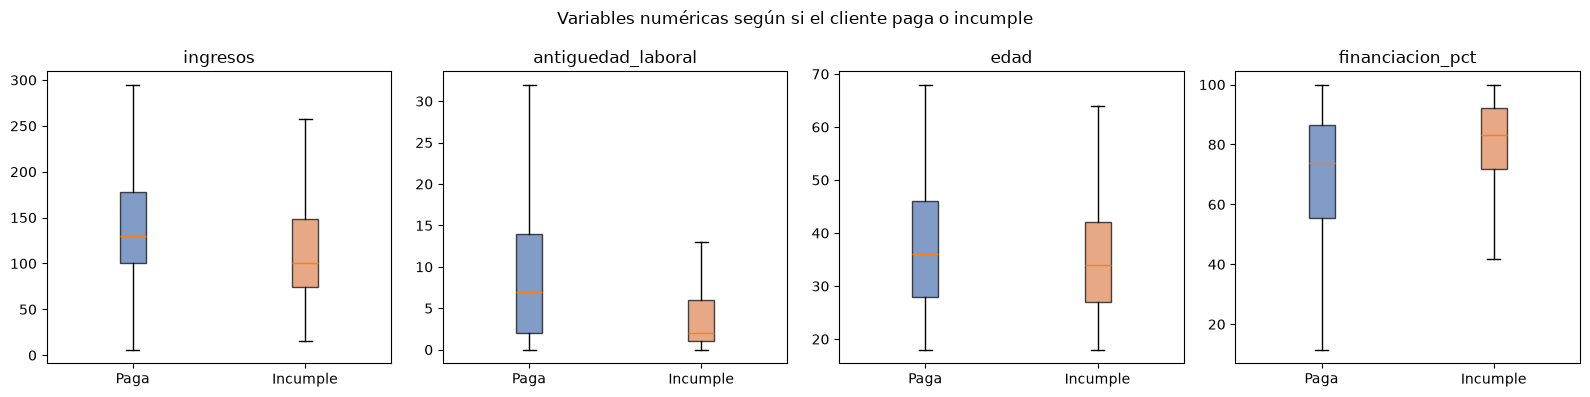

          ingresos  antiguedad_laboral  edad  financiacion_pct
incumple                                                      
Paga         130.0                 7.0  36.0              73.7
Incumple     100.0                 2.0  34.0              83.3


In [52]:
# Variables numéricas: comparación entre los que pagan y los que incumplen
num_ver = ["ingresos", "antiguedad_laboral", "edad", "financiacion_pct"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, num_ver):
    datos = [df.loc[df["incumple"] == 0, col].dropna(), df.loc[df["incumple"] == 1, col].dropna()]
    bp = ax.boxplot(datos, patch_artist=True, showfliers=False)
    ax.set_xticks([1, 2], ["Paga", "Incumple"])
    for caja, color in zip(bp["boxes"], [COLOR_PAGA, COLOR_INCUMPLE]):
        caja.set_facecolor(color); caja.set_alpha(0.7)
    ax.set_title(col)
plt.suptitle("Variables numéricas según si el cliente paga o incumple")
plt.tight_layout()
plt.show()

print(df.groupby("incumple")[num_ver].median().round(1).rename(index={0: "Paga", 1: "Incumple"}))

**Observaciones de la exploración:**

- Los clientes **con antecedentes** incumplen mucho más que los que no tienen.
- Los **independientes** y los de **medio tiempo** incumplen más que los de trabajo **fijo**.
- Los que tienen **vivienda propia** incumplen menos.
- Los que incumplen tienden a tener **menos ingresos**, **menos antigüedad laboral** y piden financiar un **mayor porcentaje** del bien.

Esto sugiere que las variables sí tienen información útil para el modelo.

## 5. División en datos de entrenamiento y prueba

- **80 %** para entrenar y **20 %** para probar.
- `stratify=y` para que ambos conjuntos tengan la misma proporción de clientes que incumplen.
- `random_state=42` para que la división sea siempre la misma.

In [53]:
X = df.drop(columns="incumple")
y = df["incumple"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)

print("Entrenamiento:", X_train.shape, f"- {y_train.mean():.1%} incumple")
print("Prueba:       ", X_test.shape, f"- {y_test.mean():.1%} incumple")

Entrenamiento: (3563, 14) - 28.2% incumple
Prueba:        (891, 14) - 28.2% incumple


## 6. Implementación del modelo

Se arma un `Pipeline` con dos partes:

**a) Preprocesamiento (`ColumnTransformer`)**
- Numéricas: se llenan los faltantes con la **mediana** (y se agrega una columna que indica si el dato faltaba) y luego se **estandarizan** (media 0, desviación 1). El escalado es necesario porque la regresión logística de scikit-learn usa regularización L2 por defecto.
- Categóricas: se llenan los faltantes con la **moda** y se pasan a variables dummy con **one-hot encoding** (se elimina la primera categoría de cada variable para usarla como referencia).

**b) Modelo:** `LogisticRegression` con los parámetros por defecto (regularización L2, `C = 1`) y `max_iter=1000` para asegurar que converja.

In [54]:
columnas_num = ["antiguedad_laboral", "plazo_meses", "edad", "gastos", "ingresos",
                "activos", "deuda", "monto_solicitado", "precio_bien", "financiacion_pct"]
columnas_cat = ["vivienda", "estado_civil", "antecedentes", "tipo_trabajo"]

preprocesamiento = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median", add_indicator=True)),
        ("escalar", StandardScaler()),
    ]), columnas_num),
    ("cat", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ]), columnas_cat),
])

modelo = Pipeline([
    ("prep", preprocesamiento),
    ("reglog", LogisticRegression(max_iter=1000, random_state=SEMILLA)),
])

# Entrenamiento: el modelo aprende los coeficientes usando solo X_train
modelo.fit(X_train, y_train)

n_vars = len(modelo.named_steps["prep"].get_feature_names_out())
print("Modelo entrenado. Variables que usa después del preprocesamiento:", n_vars)

Modelo entrenado. Variables que usa después del preprocesamiento: 26


## 7. Predicciones con `predict()` y `predict_proba()`

- `predict_proba(X)` devuelve, para cada cliente, la probabilidad de cada clase: columna 0 = P(paga) y columna 1 = **P(incumple)**.
- `predict(X)` devuelve directamente la clase (0 o 1). Internamente usa un **umbral de 0.5**: si P(incumple) ≥ 0.5 predice 1.

In [55]:
y_pred = modelo.predict(X_test)                 # clase predicha (0 = paga, 1 = incumple)
y_proba = modelo.predict_proba(X_test)[:, 1]    # probabilidad de incumplir

# Primeros 10 clientes del conjunto de prueba
muestra = pd.DataFrame({
    "real": y_test.values[:10],
    "predict()": y_pred[:10],
    "P(paga)": modelo.predict_proba(X_test)[:10, 0].round(3),
    "P(incumple)": y_proba[:10].round(3),
}, index=X_test.index[:10])
muestra

,real,predict(),P(paga),P(incumple)
2533,0,0,0.830,0.170
1211,0,0,0.891,0.109
1788,0,1,0.421,0.579
497,1,0,0.542,0.458
4220,1,1,0.377,0.623
751,0,0,0.998,0.002
373,0,0,0.806,0.194
49,0,0,0.989,0.011
2430,1,1,0.099,0.901
4440,0,0,0.901,0.099


In [56]:
# Ejemplo: dos solicitudes nuevas inventadas para ver cómo responde el modelo
nuevos = pd.DataFrame([
    # Cliente A: trabajo fijo, vivienda propia, sin antecedentes, financia el 60 %
    {"antiguedad_laboral": 12, "vivienda": "propia", "plazo_meses": 36, "edad": 45,
     "estado_civil": "casado", "antecedentes": "no", "tipo_trabajo": "fijo",
     "gastos": 60, "ingresos": 200, "activos": 8000, "deuda": 0,
     "monto_solicitado": 900, "precio_bien": 1500},
    # Cliente B: independiente, alquila, con antecedentes, financia el 95 %
    {"antiguedad_laboral": 1, "vivienda": "alquiler", "plazo_meses": 60, "edad": 24,
     "estado_civil": "soltero", "antecedentes": "si", "tipo_trabajo": "independiente",
     "gastos": 60, "ingresos": 90, "activos": 0, "deuda": 0,
     "monto_solicitado": 1400, "precio_bien": 1470},
], index=["Cliente A", "Cliente B"])
nuevos["financiacion_pct"] = 100 * nuevos["monto_solicitado"] / nuevos["precio_bien"]

pd.DataFrame({
    "predict()": modelo.predict(nuevos),
    "P(incumple)": modelo.predict_proba(nuevos)[:, 1].round(3),
}, index=nuevos.index)

,predict(),P(incumple)
Cliente A,0,0.026
Cliente B,1,0.914


## 8. Evaluación del modelo

Se evalúa sobre el **conjunto de prueba** (datos que el modelo no vio al entrenar):

- **Accuracy:** % total de aciertos.
- **Matriz de confusión:** cuántos aciertos y errores hay de cada tipo.
- **Precision (clase 1):** de los clientes que el modelo marcó como "incumple", ¿cuántos realmente incumplieron?
- **Recall (clase 1):** de todos los que realmente incumplieron, ¿cuántos detectó el modelo?
- **F1-score:** balance entre Precision y Recall.

In [57]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
base = 1 - y_test.mean()   # accuracy de decir siempre "paga"

print(f"Accuracy : {acc:.3f}   (modelo ingenuo que siempre dice 'paga': {base:.3f})")
print(f"Precision: {prec:.3f}")
print(f"Recall   : {rec:.3f}")
print(f"F1-score : {f1:.3f}")
print(f"AUC-ROC  : {auc:.3f}")
print()
print(classification_report(y_test, y_pred, target_names=["Paga (0)", "Incumple (1)"], digits=3))

Accuracy : 0.827   (modelo ingenuo que siempre dice 'paga': 0.718)
Precision: 0.754
Recall   : 0.574
F1-score : 0.652
AUC-ROC  : 0.842

              precision    recall  f1-score   support

    Paga (0)      0.847     0.927     0.885       640
Incumple (1)      0.754     0.574     0.652       251

    accuracy                          0.827       891
   macro avg      0.801     0.750     0.768       891
weighted avg      0.821     0.827     0.819       891



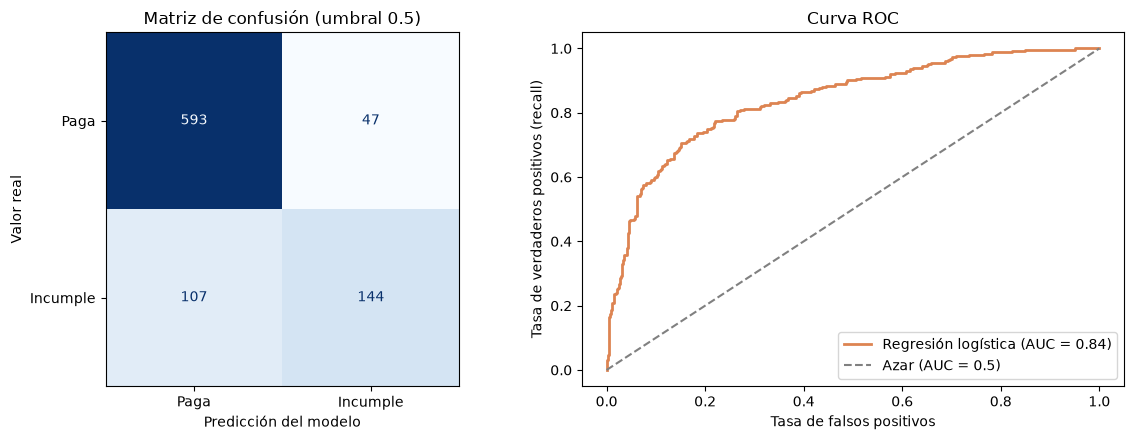

Verdaderos negativos (paga y dijo paga):        593
Falsos positivos   (paga y dijo incumple):      47
Falsos negativos   (incumple y dijo paga):      107
Verdaderos positivos (incumple y dijo incumple): 144


In [58]:
cm = confusion_matrix(y_test, y_pred)
vn, fp, fn, vp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["Paga", "Incumple"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matriz de confusión (umbral 0.5)")
axes[0].set_xlabel("Predicción del modelo"); axes[0].set_ylabel("Valor real")

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color=COLOR_INCUMPLE, lw=2, label=f"Regresión logística (AUC = {auc:.2f})")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Azar (AUC = 0.5)")
axes[1].set_title("Curva ROC")
axes[1].set_xlabel("Tasa de falsos positivos"); axes[1].set_ylabel("Tasa de verdaderos positivos (recall)")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"Verdaderos negativos (paga y dijo paga):        {vn}")
print(f"Falsos positivos   (paga y dijo incumple):      {fp}")
print(f"Falsos negativos   (incumple y dijo paga):      {fn}")
print(f"Verdaderos positivos (incumple y dijo incumple): {vp}")

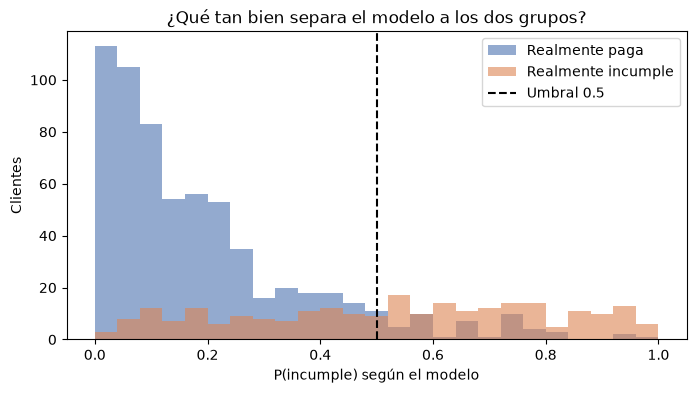

In [59]:
# Distribución de las probabilidades que da el modelo según la clase real
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, 1, 26)
ax.hist(y_proba[y_test == 0], bins=bins, alpha=0.6, color=COLOR_PAGA, label="Realmente paga")
ax.hist(y_proba[y_test == 1], bins=bins, alpha=0.6, color=COLOR_INCUMPLE, label="Realmente incumple")
ax.axvline(0.5, color="black", ls="--", label="Umbral 0.5")
ax.set_xlabel("P(incumple) según el modelo"); ax.set_ylabel("Clientes")
ax.set_title("¿Qué tan bien separa el modelo a los dos grupos?")
ax.legend()
plt.show()

## 9. Ajuste del umbral de decisión

`predict()` usa 0.5 como umbral, pero en crédito **no todos los errores cuestan lo mismo**:

- **Falso negativo:** se aprueba a alguien que no paga → el banco pierde el dinero prestado.
- **Falso positivo:** se rechaza a alguien que sí pagaba → el banco deja de ganar los intereses.

Normalmente el falso negativo es más caro, así que conviene revisar qué pasa si se **baja el umbral**.

,accuracy,precision,recall,f1,falsos_neg,falsos_pos
umbral,,,,,,
0.20,0.696,0.477,0.833,0.607,42,229
0.25,0.753,0.542,0.797,0.645,51,169
0.30,0.777,0.580,0.749,0.654,63,136
0.35,0.796,0.619,0.717,0.664,71,111
0.40,0.809,0.659,0.669,0.664,83,87
0.45,0.815,0.697,0.606,0.648,99,66
0.50,0.827,0.754,0.574,0.652,107,47
0.55,0.813,0.759,0.490,0.596,128,39
0.60,0.809,0.791,0.438,0.564,141,29


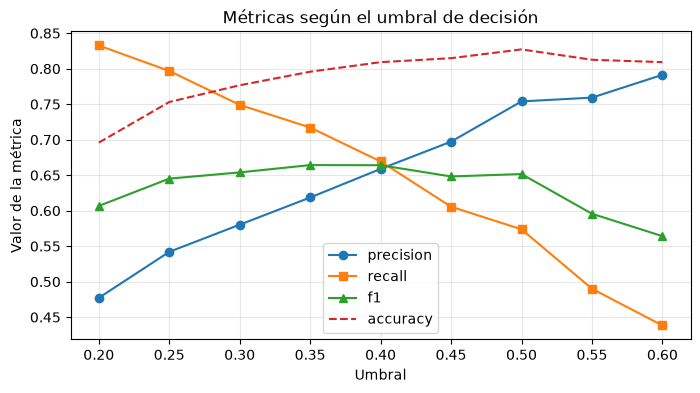

In [60]:
umbrales = np.arange(0.20, 0.65, 0.05)
filas = []
for u in umbrales:
    pred_u = (y_proba >= u).astype(int)     # misma idea que predict(), pero con otro umbral
    filas.append({
        "umbral": round(u, 2),
        "accuracy": accuracy_score(y_test, pred_u),
        "precision": precision_score(y_test, pred_u, zero_division=0),
        "recall": recall_score(y_test, pred_u),
        "f1": f1_score(y_test, pred_u),
        "falsos_neg": int(((pred_u == 0) & (y_test == 1)).sum()),
        "falsos_pos": int(((pred_u == 1) & (y_test == 0)).sum()),
    })
tabla_umbral = pd.DataFrame(filas).set_index("umbral")
display(tabla_umbral.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
for col, est in [("precision", "-o"), ("recall", "-s"), ("f1", "-^"), ("accuracy", "--")]:
    ax.plot(tabla_umbral.index, tabla_umbral[col], est, label=col)
ax.set_xlabel("Umbral"); ax.set_ylabel("Valor de la métrica")
ax.set_title("Métricas según el umbral de decisión")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

Umbral elegido: 0.35
              precision    recall  f1-score   support

    Paga (0)      0.882     0.827     0.853       640
Incumple (1)      0.619     0.717     0.664       251

    accuracy                          0.796       891
   macro avg      0.750     0.772     0.759       891
weighted avg      0.808     0.796     0.800       891



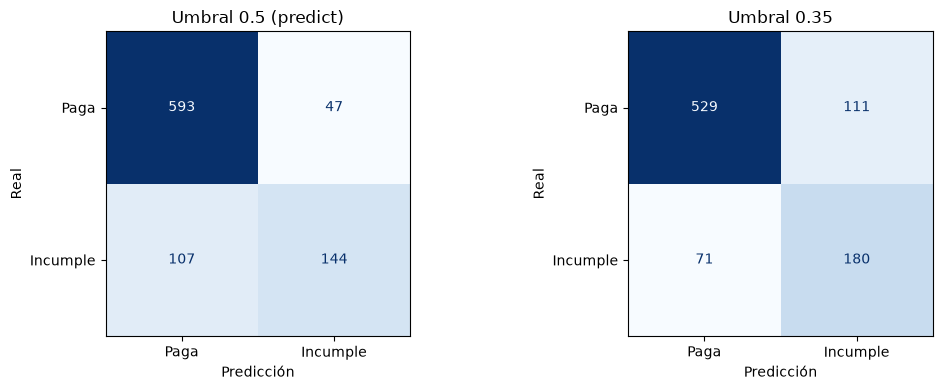

In [61]:
# Se elige el umbral con mejr F1 (mejor balance entre detectar morosos y no rechazar buenos clientes)
umbral_elegido = tabla_umbral["f1"].idxmax()
pred_final = (y_proba >= umbral_elegido).astype(int)
print(f"Umbral elegido: {umbral_elegido}")
print(classification_report(y_test, pred_final, target_names=["Paga (0)", "Incumple (1)"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (titulo, pr) in zip(axes, [("Umbral 0.5 (predict)", y_pred), (f"Umbral {umbral_elegido}", pred_final)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pr), display_labels=["Paga", "Incumple"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(titulo); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

## 10. Interpretación de los coeficientes (odds ratios)

En la regresión logística cada coeficiente β indica cuánto cambian los **log-odds** de incumplir. Para leerlo más fácil se usa el **odds ratio = e^β**:

- **OR > 1:** la variable **aumenta** las chances de incumplir.
- **OR < 1:** la variable **disminuye** las chances de incumplir.
- **OR = 1:** no tiene efecto.

Como las variables numéricas se estandarizaron, su OR se interpreta como el efecto de **subir una desviación estándar**. En las categóricas, el OR compara contra la categoría de referencia (la primera, que se eliminó en el one-hot).

In [62]:
nombres = modelo.named_steps["prep"].get_feature_names_out()
nombres = [n.replace("num__", "").replace("cat__", "") for n in nombres]
coefs = modelo.named_steps["reglog"].coef_[0]

tabla_coef = pd.DataFrame({"variable": nombres, "coeficiente": coefs, "odds_ratio": np.exp(coefs)})
tabla_coef = tabla_coef.sort_values("coeficiente", ascending=False).reset_index(drop=True)
print("Intercepto:", round(modelo.named_steps["reglog"].intercept_[0], 3))
display(tabla_coef.round(3))

Intercepto: -1.742


,variable,coeficiente,odds_ratio
0,antecedentes_si,1.737,5.679
1,tipo_trabajo_medio_tiempo,1.382,3.985
2,estado_civil_separado,1.214,3.366
3,tipo_trabajo_otro,0.690,1.993
4,financiacion_pct,0.508,1.662
5,estado_civil_viudo,0.487,1.628
6,vivienda_otra,0.442,1.556
7,estado_civil_divorciado,0.385,1.470
8,tipo_trabajo_independiente,0.380,1.463
9,missingindicator_ingresos,0.339,1.404


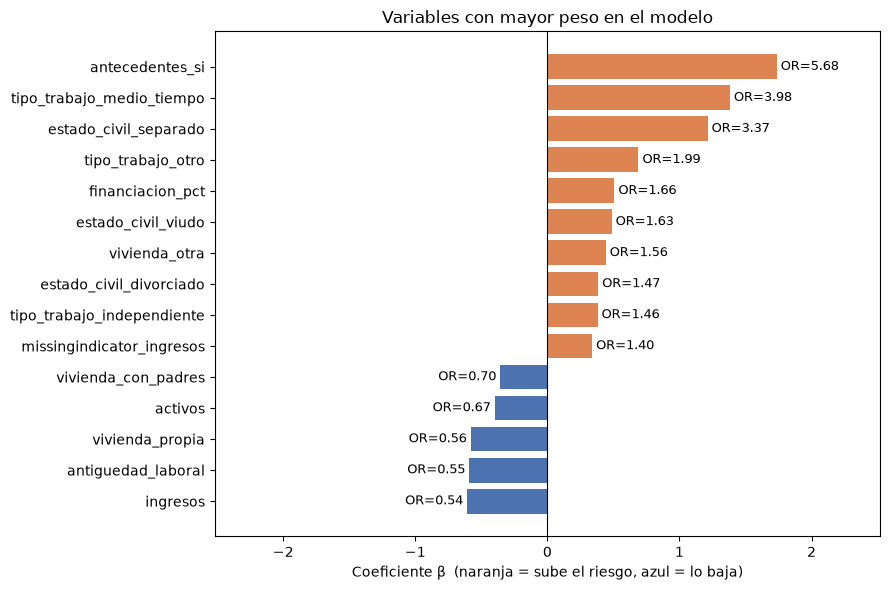

In [63]:
# Gráfico de los 15 coeficientes con mayor efecto (en valor absoluto)
top = tabla_coef.reindex(tabla_coef["coeficiente"].abs().sort_values(ascending=False).index).head(15)
top = top.sort_values("coeficiente")
colores = [COLOR_INCUMPLE if c > 0 else COLOR_PAGA for c in top["coeficiente"]]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["variable"], top["coeficiente"], color=colores)
ax.axvline(0, color="black", lw=0.8)
for i, (c, o) in enumerate(zip(top["coeficiente"], top["odds_ratio"])):
    ax.text(c + (0.03 if c > 0 else -0.03), i, f"OR={o:.2f}", va="center", ha="left" if c > 0 else "right", fontsize=9)
ax.set_xlabel("Coeficiente β  (naranja = sube el riesgo, azul = lo baja)")
ax.set_title("Variables con mayor peso en el modelo")
xmax = top["coeficiente"].abs().max() * 1.45
ax.set_xlim(-xmax, xmax)
plt.tight_layout()
plt.show()

## 11. Análisis de errores

Se revisan los clientes en los que el modelo se equivocó (con el umbral 0.5 de `predict)`), para entender qué tipo de perfiles le cuestan.

In [64]:
resultado = X_test.copy()
resultado["real"] = y_test
resultado["prediccion"] = y_pred
resultado["P_incumple"] = y_proba

def tipo(r):
    if r.real == 1 and r.prediccion == 1: return "VP"
    if r.real == 0 and r.prediccion == 0: return "VN"
    if r.real == 0 and r.prediccion == 1: return "FP"
    return "FN"
resultado["tipo"] = resultado.apply(tipo, axis=1)

# Perfil promedio de cada grupo
perfil = resultado.groupby("tipo").agg(
    clientes=("real", "size"),
    P_incumple_media=("P_incumple", "mean"),
    ingresos_mediana=("ingresos", "median"),
    antiguedad_mediana=("antiguedad_laboral", "median"),
    financiacion_media=("financiacion_pct", "mean"),
    con_antecedentes_pct=("antecedentes", lambda s: (s == "si").mean() * 100),
).loc[["VN", "FP", "FN", "VP"]]
display(perfil.round(2))

# Los 5 falsos negativos en los que el modelo estaba más "seguro" de que pagarían
print("Falsos negativos con menor probabilidad asignada:")
display(resultado[resultado["tipo"] == "FN"].sort_values("P_incumple")
        [["edad", "tipo_trabajo", "vivienda", "antecedentes", "ingresos", "antiguedad_laboral", "P_incumple"]].head(5).round(3))

,clientes,P_incumple_media,ingresos_mediana,antiguedad_mediana,financiacion_media,con_antecedentes_pct
tipo,,,,,,
VN,593,0.15,132.0,7.0,68.94,7.76
FP,47,0.67,108.0,2.0,83.07,38.30
FN,107,0.26,107.0,3.0,73.35,12.15
VP,144,0.73,118.0,1.0,81.88,53.47


Falsos negativos con menor probabilidad asignada:


,edad,tipo_trabajo,vivienda,antecedentes,ingresos,antiguedad_laboral,P_incumple
165,58,independiente,propia,si,400.0,6,0.014
4112,28,fijo,privada,no,165.0,2,0.036
112,51,independiente,propia,no,300.0,20,0.040
3326,54,fijo,propia,si,352.0,2,0.049
821,50,fijo,propia,no,210.0,22,0.053


## 12. Conclusiones

**Sobre el modelo**

- La regresión logística logró un **accuracy de 82,7 %** en datos que no vio al entrenar, frente al 71,8 % de un modelo "ingenuo" que siempre dice que el cliente paga. Es decir, sí aprende algo útil de los datos.
- El **AUC-ROC de 0,84** indica que el modelo ordena bien a los clientes: en la mayoría de los casos le asigna más probabilidad de incumplir a un moroso real que a un buen pagador.
- Con el umbral por defecto de 0,5 (`predict()`), la **precision es 0,75** (cuando dice "incumple", acierta 3 de cada 4 veces), pero el **recall es solo 0,57**: se le escapan 107 de los 251 morosos del conjunto de prueba.

**Sobre el umbral**

- Como aprobar a un cliente que no paga suele salir más caro que rechazar a uno bueno, se probó bajar el umbral. Con **0,35** el recall sube a **0,72** (se detectan 180 morosos en vez de 144) y el F1 mejora un poco (0,664 frente a 0,652), a cambio de rechazar a más buenos clientes (111 falsos positivos en vez de 47).
- La elección final del umbral no es técnica sino de negocio: depende de cuánto pierde el banco por cada crédito impagado y cuánto deja de ganar por cada cliente rechazado.

**Sobre las variables**

- El factor que más aumenta el riesgo es **tener antecedentes** (multiplica los odds de incumplir por ≈ 5,7), seguido del **trabajo de medio tiempo** (≈ 4,0) y un **% de financiación** alto.
- Lo que más reduce el riesgo es tener **más ingresos**, **más antigüedad laboral**, **vivienda propia** y **más activos**.
- Estos resultados coinciden con lo observado en la exploración y con la lógica del negocio, lo que da confianza en el modelo.

**Sobre los errores**

- Los falsos negativos (morosos que el modelo creyó buenos) tienen un perfil "de buen cliente": pocos antecedentes (12 %), financiación moderada (73 %) y probabilidad media asignada de solo 0,26. Con los datos disponibles es difícil distinguirlos; probablemente incumplieron por causas que no están en la solicitud (pérdida de empleo, imprevistos, etc.).
- Los falsos positivos se parecen a los morosos: baja antigüedad, financiación alta (83 %) y muchos con antecedentes (38 %).

**Limitaciones y mejoras posibles**

- El dataset es pequeño (4.454 clientes), antiguo y de otro país; un modelo real tendría que entrenarse con datos propios y recientes.
- Algunas categorías tienen muy pocos casos (por ejemplo, *separado* = 38 clientes), por lo que sus coeficientes son poco estables.
- Variables como el **estado civil** pueden generar decisiones discriminatorias; en un uso real habría que evaluar si es correcto incluirlas.
- Se podría mejorar con validación cruzada para ajustar `C`, `class_weight="balanced"` para el desbalance, o comparando con otros modelos (árboles, random forest).

**En resumen:** la regresión logística es una buena herramienta para este problema porque, además de clasificar, entrega una probabilidad de impago y permite explicar con odds ratios qué hace riesgoso a un cliente.

## 13. Referencias

- Sánchez, G. (2012). *CreditScoring* [Repositorio y conjunto de datos]. GitHub. https://github.com/gastonstat/CreditScoring
- Aluja, T. Curso de Minería de Datos, Universitat Politècnica de Catalunya (origen del conjunto de datos, citado por Sánchez).
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Documentación de scikit-learn: `LogisticRegression`, https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
- James, G., Witten, D., Hastie, T. y Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2.ª ed.), cap. 4: Clasificación. Springer.
- Material de clase: presentación Semana 6 y *Ejercicio Guiado de Regresión Logística*, CADI – Universidad de Cundinamarca.